# 1.03 — Expansión de estaciones MiBici: análisis exploratorio

**Periodo de comparación:** enero–septiembre de 2026  
**Insumo:** `interim_v1` (PR1) · **Rama:** `feat/eda-station-expansion`

> **Pregunta central:** ¿cómo se comportan las estaciones con primera actividad observada en 2026 frente a las consolidadas, y qué implica la expansión para pronosticar las salidas por estación y hora del día siguiente?

Esta libreta es **exploratoria y de solo lectura** respecto de los datos. Conserva todos los viajes intermedios, incluso aquellos marcados con `flag_*`. No modifica el pipeline, no entrena modelos y no genera `processed_v1`. Los gráficos se guardan en `reports/figures/` con el prefijo `1.03-jevg-`.

**Cómo ejecutar:** abrir desde la raíz del repositorio con el kernel **mibici** y ejecutar **Run All**. Se requiere `data/interim/trips/` y `data/interim/stations.parquet`, generados mediante `make interim`.

## 1. Objetivo y preguntas

1. Comparar la intensidad de salidas de estaciones nuevas y consolidadas en los **mismos meses** de 2026.
2. Evaluar la maduración de las estaciones nuevas según los meses transcurridos desde su primera actividad observada.
3. Estimar la proporción de **horas con cero salidas válidas** sin introducir ceros antes de la activación ni durante meses sin evidencia de actividad.
4. Describir la evolución mensual por cohorte de primera actividad.
5. Evaluar cuánto cambia la distribución del objetivo horario al incorporar las estaciones nuevas.

Las conclusiones se utilizan como **evidencia para el diseño posterior**, no como decisiones definitivas del equipo sobre el tratamiento de estaciones nuevas.

## 2. Datos utilizados y definiciones

- `data/interim/stations.parquet`: identificador, primer/último mes activo, indicador `is_new_station` y retiro por actividad.
- `data/interim/trips/year=2026/`: `started_at`, `origin_station_id`, `destination_station_id`. Se leen **solo las columnas necesarias y el año 2026**.
- **Salida:** un viaje en `origin_station_id` a la hora local registrada en `started_at`, sin conversión horaria.
- **Nueva:** `is_new_station=True`; primera actividad observada desde enero de 2026.
- **Consolidada:** `is_new_station=False`, primera actividad anterior a 2026 y `is_retired_by_activity=False`, con actividad observada en 2026.
- **Actividad mensual observada:** al menos un viaje con la estación como origen **o destino** durante el mes. Es una aproximación conservadora a la operación: no confirma que la estación haya estado disponible cada hora del mes.
- **Hora válida de exposición:** hora de un mes con actividad observada, dentro de los límites de la vida observada de la estación. La tasa de ceros es **aproximada**, ya que `interim_v1` no proporciona horarios de apertura, cierres parciales ni disponibilidad por hora.

Se excluyen de los cálculos comparativos los viajes con origen ausente o sin correspondencia en `stations.parquet`; se cuantifican explícitamente. La cohorte «otras» no se mezcla con las consolidadas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'data/interim/stations.parquet').exists():
    for parent in Path.cwd().resolve().parents:
        if (parent / 'data/interim/stations.parquet').exists():
            ROOT = parent
            break
STATIONS_FILE = ROOT / 'data/interim/stations.parquet'
TRIPS_DIR = ROOT / 'data/interim/trips'
FIG_DIR = ROOT / 'reports/figures'
assert STATIONS_FILE.is_file() and TRIPS_DIR.is_dir(), 'Falta interim_v1; ejecute desde el repositorio y verifique make interim.'
FIG_DIR.mkdir(parents=True, exist_ok=True)
START, END = pd.Period('2026-01', freq='M'), pd.Period('2026-09', freq='M')
MONTHS = pd.period_range(START, END, freq='M')
COLORS = {'Nueva': '#147d89', 'Consolidada': '#db7b30'}
plt.rcParams.update({'figure.figsize': (10, 4.7), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .20, 'axes.axisbelow': True})

def save_figure(name):
    path = FIG_DIR / f'1.03-jevg-{name}.png'
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches='tight')
    plt.show()
    print(f'Figura guardada: {path.relative_to(ROOT)}')

def fmt(x, digits=1):
    return f'{x:,.{digits}f}' if pd.notna(x) else 'N/D'

### 2.1 Lectura selectiva y controles de calidad

El histórico completo contiene más de 39 millones de viajes. Esta libreta **no lo carga completo**: filtra el año 2026 y selecciona las columnas mínimas. Para evitar duplicaciones, no se reconstruyen ni se limpian los viajes. Se informa de registros sin origen, fechas fuera del periodo y estaciones sin correspondencia antes de calcular indicadores.

In [2]:
stations = pd.read_parquet(STATIONS_FILE).copy()
required_st = {'station_id','first_active_month','last_active_month','is_new_station','is_retired_by_activity'}
assert required_st.issubset(stations.columns), f'Faltan columnas: {required_st - set(stations.columns)}'
assert stations['station_id'].notna().all() and stations['station_id'].is_unique, 'IDs de estación nulos o duplicados.'

for col in ['first_active_month', 'last_active_month']:
    # PeriodIndex y strings son compatibles; los valores nulos se mantienen como NaT.
    stations[col] = pd.PeriodIndex(pd.to_datetime(stations[col].astype('string'), errors='coerce'), freq='M')
stations['is_new_station'] = stations['is_new_station'].fillna(False).astype(bool)
stations['is_retired_by_activity'] = stations['is_retired_by_activity'].fillna(False).astype(bool)

trips = pd.read_parquet(TRIPS_DIR, columns=['started_at','origin_station_id','destination_station_id'], filters=[('year','==',2026)])
trips['started_at'] = pd.to_datetime(trips['started_at'], errors='coerce')
trips['month'] = trips['started_at'].dt.to_period('M')
counts = {'viajes_leidos_2026': len(trips), 'fechas_invalidas': int(trips['started_at'].isna().sum()),
          'fuera_ene_sep': int((~trips['month'].isin(MONTHS)).sum()),
          'origen_nulo': int(trips['origin_station_id'].isna().sum())}
trips = trips.loc[trips['month'].isin(MONTHS)].copy()
station_ids = pd.Index(stations['station_id'])
counts['origen_sin_metadata_de_ciclo_de_vida'] = int((trips['origin_station_id'].notna() & ~trips['origin_station_id'].isin(station_ids)).sum())
counts['destino_sin_metadata_de_ciclo_de_vida'] = int((trips['destination_station_id'].notna() & ~trips['destination_station_id'].isin(station_ids)).sum())
print('Control de lectura y correspondencia:')
display(pd.Series(counts, name='registros').to_frame())
assert len(trips) > 0, 'No hay viajes para enero–septiembre de 2026.'
print(f'Estaciones: {len(stations)} | Nuevas en catálogo: {stations.is_new_station.sum()} | Retiradas: {stations.is_retired_by_activity.sum()}')

Control de lectura y correspondencia:


,registros
viajes_leidos_2026,3361307
fechas_invalidas,0
fuera_ene_sep,0
origen_nulo,0
origen_sin_metadata_de_ciclo_de_vida,0
destino_sin_metadata_de_ciclo_de_vida,0


Estaciones: 487 | Nuevas en catálogo: 100 | Retiradas: 16


## 3. Método y construcción de denominadores

Se utiliza una tabla compacta **estación × mes** para estimar exposición, no una tabla completa estación × hora. Un mes es elegible únicamente si presenta al menos un viaje como origen o destino; por ello, los meses de inactividad registrados no se convierten en ceros. Se construyen las horas con salidas positivas a partir de los viajes y se deducen las horas con cero como `horas_elegibles − horas_positivas`.

**Precauciones:** (a) una estación con solo llegadas puede registrar todas sus horas como cero salidas y seguir siendo elegible; (b) las estaciones nuevas se incorporan desde su primer **mes observado**, sin asumir su fecha exacta de inauguración; (c) el primer y último mes pueden contener horas anteriores a la puesta en servicio o posteriores al cierre. Por tanto, los ceros se interpretan como **estimaciones mensuales**, no como ceros operacionales confirmados hora por hora. Para modelado definitivo se requerirían calendarios de disponibilidad.

In [3]:
# Actividad de estación = al menos un origen o destino observado en el mes.
orig_month = trips.loc[trips.origin_station_id.notna(), ['origin_station_id','month']].rename(columns={'origin_station_id':'station_id'})
dest_month = trips.loc[trips.destination_station_id.notna(), ['destination_station_id','month']].rename(columns={'destination_station_id':'station_id'})
active = pd.concat([orig_month, dest_month], ignore_index=True).drop_duplicates()
active = active.loc[active.station_id.isin(station_ids)].copy()
active = active.merge(stations[['station_id','first_active_month','last_active_month','is_new_station','is_retired_by_activity']], on='station_id', how='left', validate='many_to_one')
active = active.loc[(active['month'] >= active['first_active_month']) & (active['month'] <= active['last_active_month'])].copy()
active['group'] = np.select(
    [active['is_new_station'], (~active['is_new_station']) & (active['first_active_month'] < START) & (~active['is_retired_by_activity'])],
    ['Nueva', 'Consolidada'], default='Otra / excluida')
active['hours_possible'] = active['month'].dt.days_in_month * 24

valid_orig = trips.loc[trips.origin_station_id.isin(station_ids) & trips.started_at.notna(), ['origin_station_id','started_at','month']].copy()
valid_orig = valid_orig.rename(columns={'origin_station_id':'station_id'})
valid_orig['hour'] = valid_orig['started_at'].dt.floor('h')
hourly = valid_orig.groupby(['station_id','month','hour'], observed=True).size().rename('departures').reset_index()
monthly_departures = hourly.groupby(['station_id','month'], observed=True)['departures'].sum().rename('departures_month').reset_index()
monthly_positive_hours = hourly.groupby(['station_id','month'], observed=True).size().rename('positive_hours').reset_index()

panel = active.merge(monthly_departures, on=['station_id','month'], how='left', validate='one_to_one')
panel = panel.merge(monthly_positive_hours, on=['station_id','month'], how='left', validate='one_to_one')
panel[['departures_month','positive_hours']] = panel[['departures_month','positive_hours']].fillna(0).astype('int64')
panel['zero_hours'] = panel['hours_possible'] - panel['positive_hours']
assert panel['zero_hours'].ge(0).all(), 'Exposición inconsistente: hay más horas positivas que elegibles.'
assert panel[['station_id','month']].duplicated().sum() == 0

# Solo dos grupos comparables; «otras» se cuantifican, pero no contaminan la comparación.
comparison = panel.loc[panel.group.isin(COLORS)].copy()
print('Estaciones distintas por grupo:')
display(comparison.groupby('group').agg(estaciones=('station_id','nunique'), estaciones_mes=('station_id','size'), viajes=('departures_month','sum'), horas_elegibles=('hours_possible','sum')))
print('Estaciones-mes fuera de la comparación:', int((panel.group == 'Otra / excluida').sum()))
print('Salidas con origen reconocido:', f'{len(valid_orig):,}', '| Salidas contabilizadas en panel:', f'{panel.departures_month.sum():,}')
assert int(panel.departures_month.sum()) == len(valid_orig), 'La agregación de salidas no conserva el conteo.'

Estaciones distintas por grupo:


,estaciones,estaciones_mes,viajes,horas_elegibles
group,,,,
Consolidada,371,3307,3262622,2407368
Nueva,100,352,98685,258120


Estaciones-mes fuera de la comparación: 0
Salidas con origen reconocido: 3,361,307 | Salidas contabilizadas en panel: 3,361,307


### 3.1 Verificaciones adicionales

Se verifican invariantes de agregación: cada estación–mes es única, ninguna exposición presenta horas positivas superiores a las posibles y la suma mensual de salidas coincide con el total de registros válidos por origen. Estas comprobaciones no sustituyen las pruebas del pipeline central, pero ayudan a detectar errores del notebook.

In [4]:
# Prueba autocontenida de la identidad que evita construir una matriz estación × hora.
def zero_share(hours_possible, positive_hours):
    if hours_possible <= 0 or not 0 <= positive_hours <= hours_possible:
        raise ValueError('Exposición inválida')
    return (hours_possible - positive_hours) / hours_possible
assert zero_share(48, 12) == .75
assert zero_share(24, 24) == 0
assert zero_share(24, 0) == 1

# La primera actividad observada no equivale a una fecha oficial de apertura.
assert comparison.month.between(START, END).all()
assert comparison.loc[comparison.group == 'Nueva', 'first_active_month'].ge(START).all()
assert comparison.loc[comparison.group == 'Consolidada', 'first_active_month'].lt(START).all()
print('Comprobaciones metodológicas superadas.')

Comprobaciones metodológicas superadas.


## 4. Análisis y visualizaciones

Se presentan **cinco figuras** con interpretación inmediatamente posterior. Las interpretaciones contienen métricas calculadas durante la ejecución; no se anticipan resultados que aún no se hayan observado.

### 4.1 Figura 1 — Intensidad de salidas en meses comparables

Se compara la intensidad mensual como **salidas por estación y día elegible**, evitando que las estaciones consolidadas parezcan más activas únicamente por ser más numerosas o tener mayor exposición. La exposición se estima a partir de los meses con actividad observada.

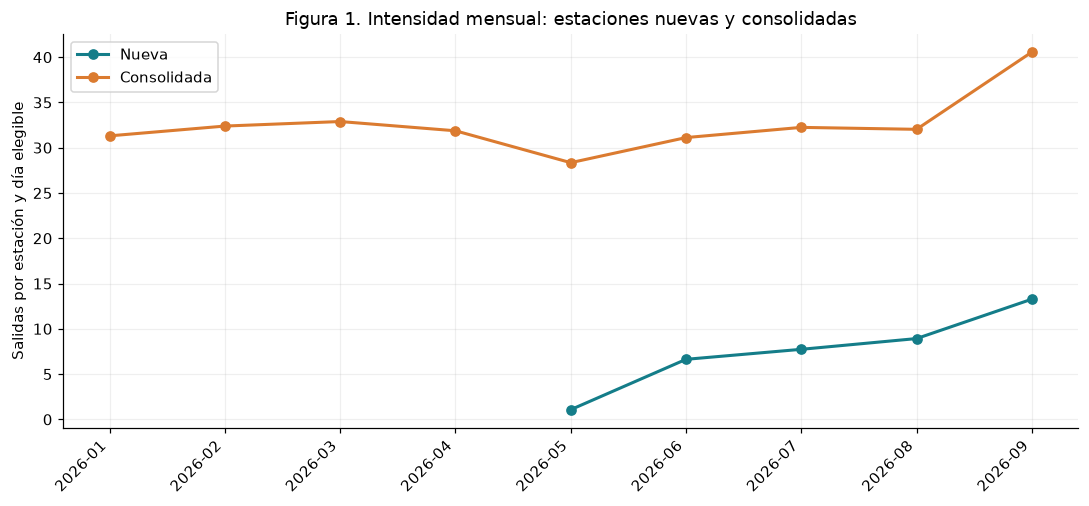

Figura guardada: reports/figures/1.03-jevg-monthly-intensity.png


In [5]:
month_group = comparison.groupby(['month','group'], observed=True).agg(departures=('departures_month','sum'), hours=('hours_possible','sum'), stations=('station_id','nunique')).reset_index()
month_group['departures_per_station_day'] = month_group['departures'] / (month_group['hours'] / 24)
fig, ax = plt.subplots()
for group, color in COLORS.items():
    d = month_group.loc[month_group.group == group].set_index('month').reindex(MONTHS)
    ax.plot(range(len(MONTHS)), d['departures_per_station_day'], marker='o', linewidth=2, color=color, label=group)
ax.set_xticks(range(len(MONTHS)), [str(m) for m in MONTHS], rotation=45, ha='right')
ax.set_ylabel('Salidas por estación y día elegible')
ax.set_title('Figura 1. Intensidad mensual: estaciones nuevas y consolidadas')
ax.legend()
save_figure('monthly-intensity')

**Interpretación de la figura 1.** La comparación se realiza sobre los mismos meses y utiliza una tasa normalizada por exposición. La distancia entre curvas indica diferencias de intensidad observada, no necesariamente un efecto causal de la expansión: ubicación, demanda local y disponibilidad pueden diferir entre estaciones. La celda siguiente cuantifica la diferencia global.

In [6]:
g1 = comparison.groupby('group').agg(departures=('departures_month','sum'), hours=('hours_possible','sum'))
g1['per_day'] = g1.departures / (g1.hours / 24)
ratio_intensity = g1.loc['Nueva','per_day'] / g1.loc['Consolidada','per_day'] if {'Nueva','Consolidada'}.issubset(g1.index) and g1.loc['Consolidada','per_day'] else np.nan
display(g1)
display(Markdown(f'**Resultado cuantitativo:** razón de intensidad nueva/consolidada = **{fmt(ratio_intensity, 3)}**. Una razón inferior a 1 indica menor intensidad media observada en las nuevas; no demuestra que la antigüedad sea su causa.'))

,departures,hours,per_day
group,,,
Consolidada,3262622,2407368,32.526364
Nueva,98685,258120,9.175732


**Resultado cuantitativo:** razón de intensidad nueva/consolidada = **0.282**. Una razón inferior a 1 indica menor intensidad media observada en las nuevas; no demuestra que la antigüedad sea su causa.

### 4.2 Figura 2 — Maduración por edad observada

Se define edad 0 como el **primer mes con actividad observada**. La intensidad por edad se calcula usando los meses activos disponibles de cada cohorte; la muestra disminuye con la edad porque las incorporaciones recientes todavía no han acumulado meses de observación (**censura por la derecha**). El referente consolidado corresponde a su intensidad ponderada durante los mismos meses calendario de 2026.

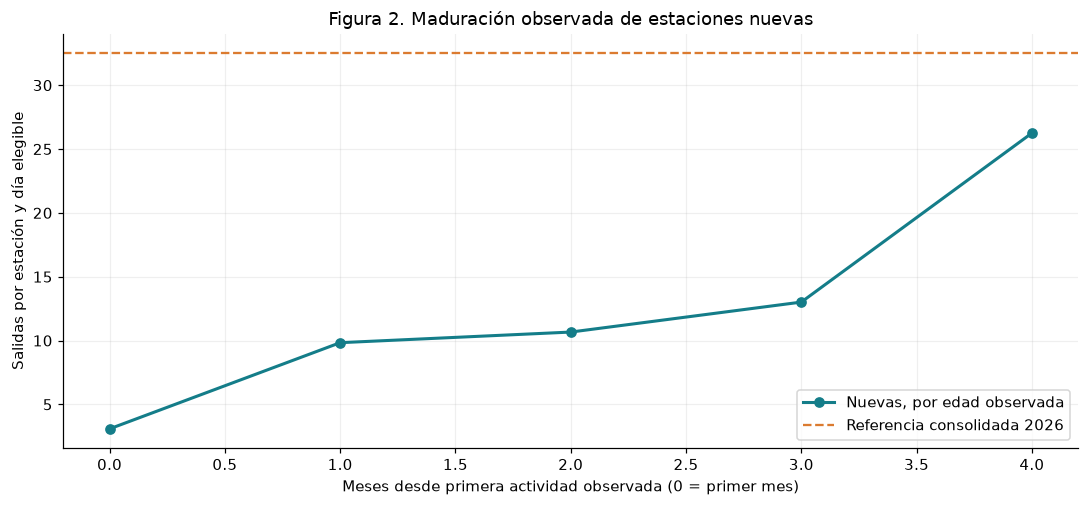

Figura guardada: reports/figures/1.03-jevg-maturation-curve.png


In [7]:
new_panel = comparison.loc[comparison.group == 'Nueva'].copy()
new_panel['age_months'] = (new_panel.month.dt.year - new_panel.first_active_month.dt.year)*12 + (new_panel.month.dt.month - new_panel.first_active_month.dt.month)
assert new_panel.age_months.ge(0).all()
ages = new_panel.groupby('age_months').agg(departures=('departures_month','sum'), hours=('hours_possible','sum'), stations=('station_id','nunique')).reset_index()
ages['per_day'] = ages.departures / (ages.hours / 24)
ref_consolidated = g1.loc['Consolidada','per_day'] if 'Consolidada' in g1.index else np.nan
fig, ax = plt.subplots()
ax.plot(ages.age_months, ages.per_day, marker='o', color=COLORS['Nueva'], linewidth=2, label='Nuevas, por edad observada')
if pd.notna(ref_consolidated):
    ax.axhline(ref_consolidated, linestyle='--', color=COLORS['Consolidada'], label='Referencia consolidada 2026')
ax.set_xlabel('Meses desde primera actividad observada (0 = primer mes)')
ax.set_ylabel('Salidas por estación y día elegible')
ax.set_title('Figura 2. Maduración observada de estaciones nuevas')
ax.legend()
save_figure('maturation-curve')

**Interpretación de la figura 2.** Una pendiente positiva es compatible con maduración, pero también puede reflejar cambios en la composición de cohortes: las estaciones con edades altas pertenecen a incorporaciones más tempranas. La referencia consolidada es descriptiva y no constituye una meta obligatoria. No debe afirmarse que una estación «alcanza» un nivel estable sin comprobar persistencia y tamaño muestral.

In [8]:
display(ages[['age_months','stations','per_day']].rename(columns={'age_months':'edad_meses','stations':'estaciones_observadas','per_day':'salidas_por_dia'}))
threshold = .8 * ref_consolidated if pd.notna(ref_consolidated) else np.nan
candidates = ages.loc[ages.per_day.ge(threshold) & ages.stations.ge(5)] if pd.notna(threshold) else ages.iloc[0:0]
first_cross = int(candidates.age_months.min()) if len(candidates) else None
display(Markdown(f'**Indicador exploratorio:** primer mes observado con intensidad ≥80 % de la referencia consolidada y ≥5 estaciones: **{first_cross if first_cross is not None else "no identificado"}**. Es un cruce descriptivo, **no** una estimación robusta del tiempo individual de maduración.'))

,edad_meses,estaciones_observadas,salidas_por_dia
0,0,100,3.084835
1,1,99,9.833717
2,2,84,10.665503
3,3,57,13.012776
4,4,12,26.250000


**Indicador exploratorio:** primer mes observado con intensidad ≥80 % de la referencia consolidada y ≥5 estaciones: **4**. Es un cruce descriptivo, **no** una estimación robusta del tiempo individual de maduración.

### 4.3 Figura 3 — Proporción de ceros horarios estimados

La tasa se obtiene como `1 − horas con ≥1 salida / horas elegibles`, ponderada por las horas de exposición de cada grupo. Se consideran únicamente meses con evidencia de actividad como origen o destino, sin rellenar meses inactivos. La exposición del primer mes puede incluir horas previas a la apertura real; por ello, la estimación debe interpretarse con cautela.

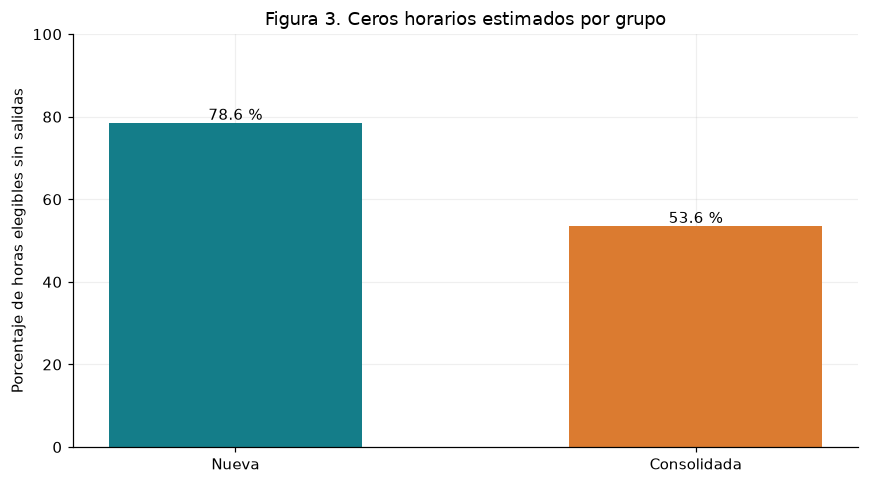

Figura guardada: reports/figures/1.03-jevg-valid-zero-share.png


In [9]:
zero_stats = comparison.groupby('group').agg(zero_hours=('zero_hours','sum'), possible_hours=('hours_possible','sum'), positive_hours=('positive_hours','sum'), stations=('station_id','nunique'))
zero_stats['zero_pct'] = 100 * zero_stats.zero_hours / zero_stats.possible_hours
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [g for g in COLORS if g in zero_stats.index]
bars = ax.bar(labels, zero_stats.loc[labels,'zero_pct'], color=[COLORS[g] for g in labels], width=.55)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.7, f'{bar.get_height():.1f} %', ha='center')
ax.set_ylim(0, max(100, float(zero_stats.zero_pct.max())+8))
ax.set_ylabel('Porcentaje de horas elegibles sin salidas')
ax.set_title('Figura 3. Ceros horarios estimados por grupo')
save_figure('valid-zero-share')

**Interpretación de la figura 3.** Una tasa mayor de ceros en estaciones nuevas implicaría un objetivo más disperso y posibles dificultades para predecir salidas en etapas tempranas. No se incluyen periodos anteriores a la primera actividad ni meses sin viajes; sin embargo, **no puede certificarse la disponibilidad operativa de cada hora** solo con registros de viajes.

In [10]:
display(zero_stats)
if {'Nueva','Consolidada'}.issubset(zero_stats.index):
    delta_zero = zero_stats.loc['Nueva','zero_pct'] - zero_stats.loc['Consolidada','zero_pct']
    display(Markdown(f'**Resultado cuantitativo:** diferencia nuevas − consolidadas = **{fmt(delta_zero,2)} puntos porcentuales** de horas sin salidas estimadas.'))

,zero_hours,possible_hours,positive_hours,stations,zero_pct
group,,,,,
Consolidada,1289933,2407368,1117435,371,53.582709
Nueva,202811,258120,55309,100,78.572369


**Resultado cuantitativo:** diferencia nuevas − consolidadas = **24.99 puntos porcentuales** de horas sin salidas estimadas.

### 4.4 Figura 4 — Cohortes de primera actividad en 2026

Las cohortes se definen por el mes de primera actividad observada. La figura presenta intensidad por estación y día elegible, no totales brutos, para evitar que cohortes con distinto número de estaciones sean comparadas únicamente por su tamaño. Una celda ausente significa **sin observación elegible**, no cero.

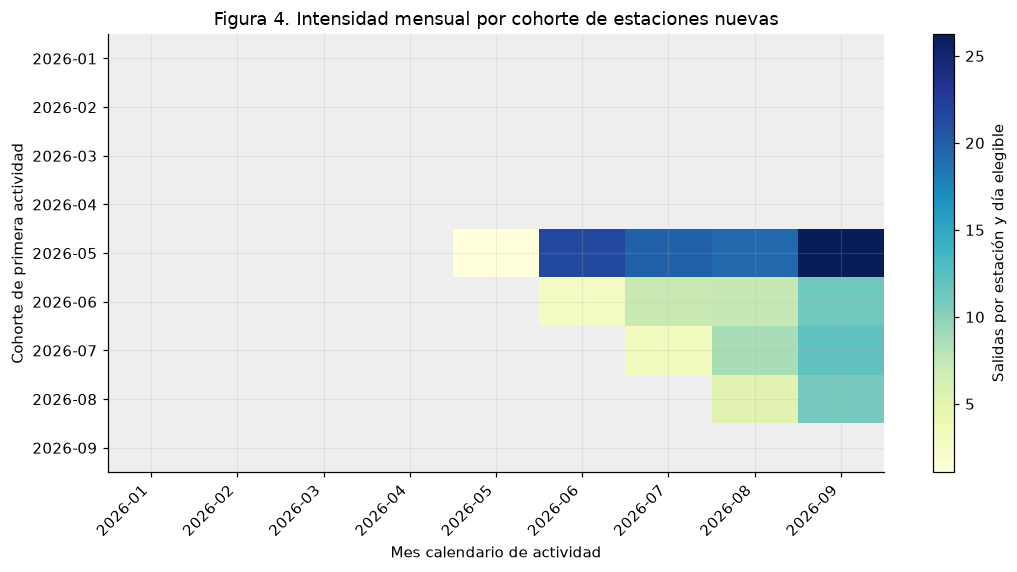

Figura guardada: reports/figures/1.03-jevg-cohort-heatmap.png


In [11]:
cohort_stats = new_panel.groupby(['first_active_month','month']).agg(departures=('departures_month','sum'), hours=('hours_possible','sum'), stations=('station_id','nunique')).reset_index()
cohort_stats['per_day'] = cohort_stats.departures / (cohort_stats.hours/24)
cohort_matrix = cohort_stats.pivot(index='first_active_month', columns='month', values='per_day').reindex(index=MONTHS, columns=MONTHS)
fig, ax = plt.subplots(figsize=(10, 5.3))
masked = np.ma.masked_invalid(cohort_matrix.to_numpy(dtype=float))
cm = plt.colormaps['YlGnBu'].copy(); cm.set_bad('#eeeeee')
im = ax.imshow(masked, aspect='auto', cmap=cm)
ax.set_xticks(range(len(MONTHS)), [str(m) for m in MONTHS], rotation=45, ha='right')
ax.set_yticks(range(len(MONTHS)), [str(m) for m in MONTHS])
ax.set_xlabel('Mes calendario de actividad')
ax.set_ylabel('Cohorte de primera actividad')
ax.set_title('Figura 4. Intensidad mensual por cohorte de estaciones nuevas')
fig.colorbar(im, ax=ax, label='Salidas por estación y día elegible')
save_figure('cohort-heatmap')

**Interpretación de la figura 4.** El mapa permite distinguir incrementos dentro de una cohorte frente a cambios debidos a la entrada de nuevas cohortes. Los espacios grises no representan falta de demanda: indican periodos sin observación elegible, principalmente anteriores a la primera actividad. Las diferencias entre cohortes pueden estar asociadas a localización, calendario y composición de estaciones.

In [12]:
cohort_sizes = stations.loc[stations.is_new_station & stations.first_active_month.isin(MONTHS)].groupby('first_active_month').size().rename('estaciones_nuevas')
display(cohort_sizes.to_frame())
print('Cohortes observadas en el periodo:', len(cohort_sizes), '| Total de estaciones nuevas por cohorte:', int(cohort_sizes.sum()))

,estaciones_nuevas
first_active_month,
2026-05,12
2026-06,47
2026-07,27
2026-08,14


Cohortes observadas en el periodo: 4 | Total de estaciones nuevas por cohorte: 100


### 4.5 Figura 5 — Distribución del objetivo horario con y sin nuevas estaciones

Se compara la distribución del número de salidas por estación–hora **elegible** para: (i) estaciones consolidadas y (ii) consolidadas + nuevas. Se incorporan analíticamente los ceros, sin construir una tabla estación × hora. Las estaciones clasificadas como «otras» quedan fuera de ambos escenarios para mantener una comparación controlada.

La figura muestra la **función de distribución acumulada (FDA)** de los conteos horarios. Una FDA más alta en conteos pequeños indica mayor concentración en valores bajos. Los percentiles se calculan sobre todas las horas elegibles, incluidos ceros.

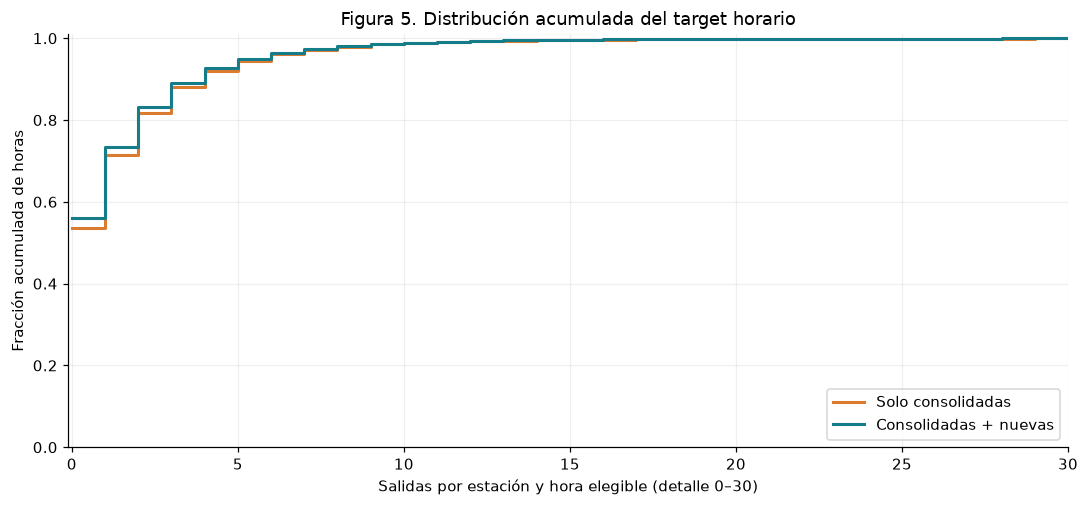

Figura guardada: reports/figures/1.03-jevg-target-distribution.png


In [13]:
# Asociar horas positivas a meses elegibles y sus grupos, sin materializar horas con cero.
hourly_comp = hourly.merge(comparison[['station_id','month','group']], on=['station_id','month'], how='inner', validate='many_to_one')
assert int(hourly_comp.groupby('group').departures.sum().sum()) == int(comparison.departures_month.sum())

def count_distribution(groups):
    subset = comparison.loc[comparison.group.isin(groups)]
    n_possible = int(subset.hours_possible.sum())
    pos = hourly_comp.loc[hourly_comp.group.isin(groups),'departures'].astype('int64')
    n_zero = n_possible - len(pos)
    assert n_zero >= 0 and n_possible > 0
    frequencies = pos.value_counts().sort_index()
    frequencies.loc[0] = n_zero
    frequencies = frequencies.sort_index()
    assert int(frequencies.sum()) == n_possible
    return frequencies, n_possible

def distribution_quantile(freq, total, p):
    c = freq.cumsum().to_numpy()
    return int(freq.index[np.searchsorted(c, p * total, side='left')])

freq_est, n_est = count_distribution(['Consolidada'])
freq_all, n_all = count_distribution(['Consolidada','Nueva'])
max_x = int(max(freq_est.index.max(), freq_all.index.max()))
fig, ax = plt.subplots()
for freq, n_total, label, color in [(freq_est,n_est,'Solo consolidadas',COLORS['Consolidada']),
                                    (freq_all,n_all,'Consolidadas + nuevas',COLORS['Nueva'])]:
    x = freq.index.to_numpy(dtype=int)
    y = freq.cumsum().to_numpy() / n_total
    ax.step(x, y, where='post', label=label, color=color, linewidth=2)
ax.set_xlim(-.1, min(max_x, 30))
ax.set_ylim(0, 1.01)
ax.set_xlabel('Salidas por estación y hora elegible (detalle 0–30)')
ax.set_ylabel('Fracción acumulada de horas')
ax.set_title('Figura 5. Distribución acumulada del target horario')
ax.legend(loc='lower right')
save_figure('target-distribution')

rows=[]
for label, f, total in [('Solo consolidadas',freq_est,n_est),('Consolidadas + nuevas',freq_all,n_all)]:
    rows.append({'escenario':label,'horas_elegibles':total,'ceros_%':100*f.loc[0]/total,
                 'media_salidas_hora':float((f.index.to_numpy(dtype=float)*f.to_numpy()).sum()/total),
                 'p50':distribution_quantile(f,total,.5),'p90':distribution_quantile(f,total,.9),
                 'p95':distribution_quantile(f,total,.95),'p99':distribution_quantile(f,total,.99)})
target_summary = pd.DataFrame(rows).set_index('escenario')

**Interpretación de la figura 5.** Las diferencias entre las dos curvas cuantifican el cambio descriptivo de la distribución del objetivo al añadir las estaciones nuevas. El gráfico se limita a 0–30 salidas por hora para visualizar la masa central; los percentiles de la tabla se calculan con **todos** los conteos, sin truncamiento. Si las curvas se parecen, la expansión podría afectar más a determinados segmentos que a la distribución agregada; ello no elimina el riesgo de *cold start* individual.

In [14]:
display(target_summary)
zero_change = target_summary.iloc[1]['ceros_%'] - target_summary.iloc[0]['ceros_%']
mean_change = target_summary.iloc[1]['media_salidas_hora'] - target_summary.iloc[0]['media_salidas_hora']
display(Markdown(f'**Resultado cuantitativo:** incorporar estaciones nuevas modifica la proporción de ceros en **{fmt(zero_change,2)} puntos porcentuales** y la media del objetivo en **{fmt(mean_change,3)} salidas por hora elegible**. La diferencia refleja composición de la red, no un efecto causal aislado.'))

,horas_elegibles,ceros_%,media_salidas_hora,p50,p90,p95,p99
escenario,,,,,,,
Solo consolidadas,2407368,53.582709,1.355265,0,4,6,11
Consolidadas + nuevas,2665488,56.002653,1.261048,0,4,5,11


**Resultado cuantitativo:** incorporar estaciones nuevas modifica la proporción de ceros en **2.42 puntos porcentuales** y la media del objetivo en **-0.094 salidas por hora elegible**. La diferencia refleja composición de la red, no un efecto causal aislado.

## 5. Hallazgos integrados

La siguiente tabla resume las cinco preguntas usando los indicadores **calculados**. Sus valores no se rellenan manualmente para evitar inconsistencias al volver a ejecutar la libreta.

In [15]:
findings = pd.DataFrame([
    {'Pregunta':'1. Intensidad nuevas vs. consolidadas','Indicador': 'Razón de salidas por estación-día', 'Resultado':fmt(ratio_intensity,3)},
    {'Pregunta':'2. Tiempo de maduración','Indicador':'Primer cruce exploratorio de 80 % (≥5 estaciones)', 'Resultado':str(first_cross) if first_cross is not None else 'No identificado'},
    {'Pregunta':'3. Horas con cero','Indicador':'Diferencia nuevas − consolidadas (p.p.)', 'Resultado':fmt(delta_zero,2) if 'delta_zero' in globals() else 'N/D'},
    {'Pregunta':'4. Crecimiento por cohorte','Indicador':'Número de cohortes observadas', 'Resultado':str(len(cohort_sizes))},
    {'Pregunta':'5. Distribución del objetivo','Indicador':'Cambio de ceros con nuevas (p.p.)', 'Resultado':fmt(zero_change,2)},
])
display(findings)

,Pregunta,Indicador,Resultado
0,1. Intensidad nuevas vs. consolidadas,Razón de salidas por estación-día,0.282
1,2. Tiempo de maduración,Primer cruce exploratorio de 80 % (≥5 estaciones),4
2,3. Horas con cero,Diferencia nuevas − consolidadas (p.p.),24.99
3,4. Crecimiento por cohorte,Número de cohortes observadas,4
4,5. Distribución del objetivo,Cambio de ceros con nuevas (p.p.),2.42


## 6. Implicaciones para el modelado y recomendaciones

1. **Evaluación estratificada:** reportar métricas de pronóstico por separado para estaciones nuevas y consolidadas, además del promedio global. Una mejora global puede ocultar errores en las incorporaciones recientes.
2. **Riesgo de *cold start*:** estudiar alternativas cuando una estación tenga poca historia: referencias por zona o por estaciones semejantes, modelos globales con atributos de estación y evaluación por edad observada. **No** se implementan aquí variables ni modelos definitivos.
3. **Ceros y exposición:** construir `processed_v1` únicamente después de acordar la regla de actividad. No rellenar horas anteriores a la activación ni meses inactivos. Si se dispone de información de aperturas, cierres y disponibilidad por hora, reemplazar la aproximación mensual de este EDA.
4. **Maduración:** no adoptar automáticamente un umbral de meses a partir del primer cruce agregado; contrastar resultados por cohorte y persistencia de la actividad, controlando el tamaño muestral y la censura temporal.
5. **Diseño de validación:** considerar particiones temporales que eviten utilizar información futura sobre el ciclo de vida de una estación. En particular, `last_active_month` y `is_retired_by_activity` son etiquetas calculadas con el histórico completo y **no deben usarse como predictores contemporáneos sin control de fuga de información**.
6. **Integración del equipo:** comunicar a Leonardo las diferencias de intensidad, proporción de ceros y distribución del objetivo para decidir el tratamiento final en `processed_v1` y en la evaluación.

Estas son **propuestas para discusión**; las decisiones de integración y el procesamiento definitivo corresponden a la etapa posterior del PR2.

## 7. Limitaciones y riesgos de interpretación

- **Apertura aproximada:** `first_active_month` es el primer mes con actividad observada, no una fecha oficial de inauguración. No se conoce la hora real de inicio del servicio.
- **Actividad no equivale a disponibilidad:** observar viajes en un mes no prueba que la estación estuviera operativa durante todas sus horas. La proporción de ceros puede sobreestimarse, especialmente en el primer mes.
- **Censura por la derecha:** las estaciones incorporadas cerca de septiembre de 2026 aún no tienen seguimiento suficiente para evaluar su maduración.
- **Comparabilidad imperfecta:** aun comparando los mismos meses, ubicación, capacidad, densidad de usuarios, demanda y fallas operativas pueden diferir entre grupos.
- **Clasificación de retiro:** el indicador `is_retired_by_activity` se define usando el histórico completo. Excluir estaciones retiradas es coherente con el plan del equipo, pero puede introducir sesgo de supervivencia; conviene revisar sensibilidad posteriormente.
- **Datos faltantes:** las estaciones sin correspondencia o sin origen válido se cuantifican y excluyen de los indicadores que requieren ciclo de vida; los viajes con flags se conservan.
- **No causalidad:** las comparaciones no demuestran que la expansión provoque diferencias de demanda. Los resultados son descriptivos.
- **Falta de exposición horaria real:** no se dispone de un calendario oficial de apertura/cierre, mantenimiento o disponibilidad. El denominador utilizado es una aproximación documentada.

## 8. Conclusión

El análisis exploratorio permitió identificar diferencias relevantes entre las estaciones nuevas y consolidadas de MiBici durante enero–septiembre de 2026. Las estaciones nuevas registraron una intensidad promedio de 9.18 salidas por estación y día elegible, frente a 32.53 en las consolidadas, equivalente a una razón de 0.282. Asimismo, presentaron una proporción estimada de horas sin salidas de 78.57 %, superior al 53.58 % observado en las estaciones consolidadas.

La incorporación de estaciones nuevas modificó la distribución agregada del objetivo predictivo: la proporción de ceros aumentó 2.42 puntos porcentuales y la media disminuyó de 1.355 a 1.261 salidas por estación y hora elegible. Estos resultados evidencian diferencias en la composición y actividad de la red que deben considerarse al diseñar y evaluar los modelos de pronóstico.

Respecto de la maduración, se identificó un crecimiento descriptivo de la intensidad con la edad observada. No obstante, la reducción progresiva del número de estaciones disponibles para el seguimiento impide establecer un tiempo general de estabilización. El cruce exploratorio del umbral de referencia en el cuarto mes debe interpretarse con cautela, dado que únicamente 12 estaciones cuentan con observaciones en ese punto.

En conjunto, los hallazgos respaldan la conveniencia de realizar evaluaciones diferenciadas por antigüedad, considerar estrategias para estaciones con historial limitado y definir cuidadosamente los periodos elegibles antes de construir el conjunto `processed_v1`. Las decisiones definitivas deberán establecerse durante la integración de resultados del equipo, considerando las limitaciones de disponibilidad operativa y censura temporal identificadas.

**Reflexión JEVG** Considero especialmente importante que la interpretación de los ceros dependa de la actividad observada: construir automáticamente todas las combinaciones estación–hora podría generar ejemplos falsos y sesgar tanto el análisis como el entrenamiento posterior. Asimismo, aprendí que comparar estaciones nuevas con consolidadas exige controlar la exposición temporal y reconocer la censura de las cohortes recientes. Por ello, los resultados de esta libreta deben informar las decisiones del equipo, no sustituir su validación operativa.

**Siguiente etapa:** revisión del PR e integración de los hallazgos para construir `processed_v1`, sin modificar aquí los datos originales ni los módulos compartidos.

## 9. Reproducibilidad y entrega

- Ejecutar con el kernel `mibici` desde la raíz del repositorio.
- Verificar que todas las celdas terminen sin errores y conservar sus resultados en el `.ipynb`.
- Confirmar que existan las cinco imágenes `reports/figures/1.03-jevg-*.png`.
- Comprobar `git status` y agregar **únicamente** el notebook y sus cinco figuras (nunca `data/raw`, `data/interim` ni reportes pesados).
- Abrir el PR desde `feat/eda-station-expansion` hacia `main`, con Leonardo como revisor.